[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_term_structure/BA_L3_term_structure.ipynb)

# BA_L3_term_structure: Volatility forecasts by horizon

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

GARCH(1,1)-t variance forecasts by horizon up to 250 days: mean reversion after a shock for the S&P 500 and gold (persistence below 1), and the forecasts made for Bitcoin on 18 September 2026 by an integrated GARCH (persistence 1, positive intercept) and by EWMA. Daily log returns 2018-2026.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** Daily log returns in %, 1 January 2018 – 18 September 2026: S&P 500 and gold (trading days), Bitcoin (every day).

**Model.** $r_t = \mu + \varepsilon_t$, $\varepsilon_t = \sigma_t z_t$, with the GARCH(1,1) recursion of Bollerslev (1986)
$$ \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 , $$
and $z_t$ i.i.d. (independent and identically distributed) Student-t with $\nu$ degrees of freedom, rescaled to variance 1 (GARCH-t).
$\alpha + \beta$ is the persistence; the parameters are estimated by maximum likelihood.

**Forecasts.** If $\alpha + \beta < 1$, $\mathrm{E}_t[\sigma^2_{t+h}] = \bar\sigma^2 + (\alpha+\beta)^{h-1}(\sigma^2_{t+1} - \bar\sigma^2)$ with long-run variance $\bar\sigma^2 = \omega/(1-\alpha-\beta)$ and half-life $\ln 0.5/\ln(\alpha+\beta)$ days.
If $\alpha + \beta = 1$ with $\omega > 0$ (integrated GARCH, IGARCH), $\mathrm{E}_t[\sigma^2_{t+h}] = \sigma^2_{t+1} + (h-1)\,\omega$; EWMA ($\omega = 0$) gives a flat forecast.

**How to read.** Left: forecast variance divided by the long-run variance after a shock that doubles the variance. Right: Bitcoin forecast volatility in % a year by horizon.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin', 'S&P 500', 'Gold']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18', 'S&P 500': '2190 days, 2018-01-02 - 2026-09-18', 'Gold': '2269 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,Bitcoin,S&P 500,Gold
mu,0.0563,0.1109,0.0535
omega,0.1442,0.0352,0.0147
alpha,0.0761,0.1616,0.0615
beta,0.9239,0.8194,0.9308
alpha + beta,1.0000,0.9810,0.9923
nu,3.1260,5.8454,4.0634


In [7]:
lam = 0.94     # RiskMetrics decay


def ewma_forecasts(r, lam=lam):
    # one-step EWMA variance forecasts: value at t = forecast for day t made at the end of day t-1;
    # started at the variance of the first 250 days; the last element is the forecast for the day after the sample
    v = r.iloc[:250].var(); out = []
    for x in r.values:
        out.append(v)
        v = lam * v + (1 - lam) * x ** 2
    return pd.Series(out, index=r.index), v

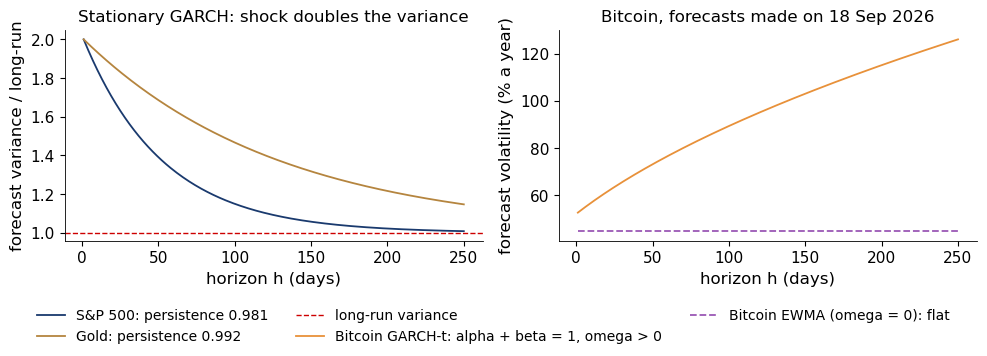

In [8]:
hz = np.arange(1, 251)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
key = {}
for k in ['S&P 500', 'Gold']:
    pr = fits[k].params; pers = pr['alpha[1]'] + pr['beta[1]']
    lr = pr['omega'] / (1 - pers)
    path_ = lr + pers ** (hz - 1) * (2 * lr - lr)
    ax[0].plot(hz, path_ / lr, color=ASSETS[k][2], label=f'{k}: persistence {pers:.3f}')
    key[k] = {'persistence alpha + beta': pers, 'half-life (days)': np.log(0.5) / np.log(pers),
              'forecast variance / long-run after 250 days': path_[-1] / lr}
ax[0].axhline(1, color=RED, ls='--', lw=1, label='long-run variance')
ax[0].set_xlabel('horizon h (days)'); ax[0].set_ylabel('forecast variance / long-run')
ax[0].set_title('Stationary GARCH: shock doubles the variance')

gb = fits['Bitcoin']
fb = gb.forecast(horizon=len(hz), reindex=False).variance.values[-1]       # E_T[sigma^2_{T+h}], h = 1..250
v = ewma_forecasts(R['Bitcoin'])[1]                                         # EWMA variance forecast for 19 Sep 2026
ax[1].plot(hz, np.sqrt(365 * fb), color=BTC, label='Bitcoin GARCH-t: alpha + beta = 1, omega > 0')
ax[1].plot(hz, np.full(len(hz), np.sqrt(365 * v)), color=ETH, ls='--', label='Bitcoin EWMA (omega = 0): flat')
ax[1].set_xlabel('horizon h (days)'); ax[1].set_ylabel('forecast volatility (% a year)')
ax[1].set_title('Bitcoin, forecasts made on 18 Sep 2026')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l3_term_structure')

**Key numbers** (as on the slide).

In [9]:
print(pd.DataFrame(key).round(3).to_string()); print()
pd.Series({'Bitcoin omega': gb.params['omega'], 'Bitcoin alpha + beta': gb.params['alpha[1]'] + gb.params['beta[1]'],
           'GARCH-t forecast volatility, h = 1 (% a year)': np.sqrt(365 * fb[0]),
           'GARCH-t forecast volatility, h = 35 (% a year)': np.sqrt(365 * fb[34]),
           'GARCH-t forecast volatility, h = 250 (% a year)': np.sqrt(365 * fb[-1]),
           'EWMA forecast volatility, every h (% a year)': np.sqrt(365 * v)}).round(3).to_frame('Bitcoin, 18 Sep 2026')

                                             S&P 500    Gold
persistence alpha + beta                       0.981   0.992
half-life (days)                              36.127  90.040
forecast variance / long-run after 250 days    1.008   1.147



,"Bitcoin, 18 Sep 2026"
Bitcoin omega,0.144
Bitcoin alpha + beta,1.000
"GARCH-t forecast volatility, h = 1 (% a year)",52.747
"GARCH-t forecast volatility, h = 35 (% a year)",67.613
"GARCH-t forecast volatility, h = 250 (% a year)",126.038
"EWMA forecast volatility, every h (% a year)",44.902
